In [16]:
import numpy as np
import pandas as pd
import time
import re
import html
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.dates as mdates
from deep_translator import GoogleTranslator
from bs4 import BeautifulSoup, Comment, MarkupResemblesLocatorWarning
from scipy.stats import mannwhitneyu
import warnings
import pickle
from tqdm import tqdm
from tqdm.notebook import tqdm
from collections import Counter
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import ComplementNB
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import classification_report, accuracy_score, average_precision_score, f1_score, precision_recall_curve
from xgboost import XGBClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from scipy.sparse import hstack
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, PrecisionRecallDisplay
from itertools import combinations
from statsmodels.stats.contingency_tables import mcnemar
from statsmodels.stats.multitest import multipletests
from sklearn.metrics import confusion_matrix
import string

### Load Dataset (with English translation)

In [17]:
# Load the clean dataset
pd.set_option('display.max_columns', None)
clean_data = pd.read_csv("all_data_with_english_translations.csv", usecols=['created_at', 'subdomain','table','label','is_spam','url_count','has_url','body_clean','language','body_english'])
clean_data['has_url'] = clean_data['has_url'].astype(int)
display(len(clean_data))
display(clean_data.head())

93323

,created_at,subdomain,table,is_spam,label,url_count,has_url,body_clean,language,body_english
0,2023-02-24 01:52:08,support,hc_answers,0,NaN,0,0,"Hi Serge, thanks for the feedback! Agreed that the side conversation notifications need to live in a place like the Home Dashboard like you suggested. Unfortunately, the existing dashboard activity stream is only designed to list specific types of Ticket events, but we do have other avenues we are currently exploring to make it easier to stay on top of the side conversation (and other) activities.",en,"Hi Serge, thanks for the feedback! Agreed that the side conversation notifications need to live in a place like the Home Dashboard like you suggested. Unfortunately, the existing dashboard activity stream is only designed to list specific types of Ticket events, but we do have other avenues we are currently exploring to make it easier to stay on top of the side conversation (and other) activities."
1,2022-06-22 20:38:15,support,hc_comments,0,NaN,0,0,1263082275569 is there a way to remove the deleted organizations from showing up in explorer? I use a report to export data and we have 500+ deleted accounts from our initial seeding that I would like to remove.,en,1263082275569 is there a way to remove the deleted organizations from showing up in explorer? I use a report to export data and we have 500+ deleted accounts from our initial seeding that I would like to remove.
2,2022-11-04 14:14:18,support,hc_comments,0,NaN,0,0,Has anybody managed to get this setup using Azure AD to create agents with a custom role?\nWe have added mappings for role (set to 'agent') and custom_role_id (set to the id of the custom role to assign) but users are always created as end-user rather than as agent.\n\nAny ideas?\nThanks,en,Has anybody managed to get this setup using Azure AD to create agents with a custom role?\nWe have added mappings for role (set to 'agent') and custom_role_id (set to the id of the custom role to assign) but users are always created as end-user rather than as agent.\n\nAny ideas?\nThanks
3,2023-04-11 07:27:27,support,hc_answers,0,NaN,0,0,"Hi Rey,\n \nI created a ticket on your behalf and will send it to you via email so we can further discuss your concern regarding your report.\n \nThank you!",en,"Hi Rey,\n \nI created a ticket on your behalf and will send it to you via email so we can further discuss your concern regarding your report.\n \nThank you!"
4,2022-05-09 16:19:22,support,hc_answers,0,NaN,0,0,I too am trying to accomplish this but haven't been able to figure it out yet. If the ticket cannot be submitted by the end user can the form filler at least be CC'd on the ticket?,en,I too am trying to accomplish this but haven't been able to figure it out yet. If the ticket cannot be submitted by the end user can the form filler at least be CC'd on the ticket?


In [18]:
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)
pd.set_option("display.max_colwidth", None)
display(len(clean_data[clean_data['label'] == 14]))

6

In [19]:
clean_data = clean_data[clean_data['label'] != 14].copy()

### Extract Features (Word Count)

In [20]:
#Add word count

clean_data['word_count'] = clean_data['body_english'].str.split().str.len()
display(clean_data.head())

,created_at,subdomain,table,is_spam,label,url_count,has_url,body_clean,language,body_english,word_count
0,2023-02-24 01:52:08,support,hc_answers,0,NaN,0,0,"Hi Serge, thanks for the feedback! Agreed that the side conversation notifications need to live in a place like the Home Dashboard like you suggested. Unfortunately, the existing dashboard activity stream is only designed to list specific types of Ticket events, but we do have other avenues we are currently exploring to make it easier to stay on top of the side conversation (and other) activities.",en,"Hi Serge, thanks for the feedback! Agreed that the side conversation notifications need to live in a place like the Home Dashboard like you suggested. Unfortunately, the existing dashboard activity stream is only designed to list specific types of Ticket events, but we do have other avenues we are currently exploring to make it easier to stay on top of the side conversation (and other) activities.",66.0
1,2022-06-22 20:38:15,support,hc_comments,0,NaN,0,0,1263082275569 is there a way to remove the deleted organizations from showing up in explorer? I use a report to export data and we have 500+ deleted accounts from our initial seeding that I would like to remove.,en,1263082275569 is there a way to remove the deleted organizations from showing up in explorer? I use a report to export data and we have 500+ deleted accounts from our initial seeding that I would like to remove.,38.0
2,2022-11-04 14:14:18,support,hc_comments,0,NaN,0,0,Has anybody managed to get this setup using Azure AD to create agents with a custom role?\nWe have added mappings for role (set to 'agent') and custom_role_id (set to the id of the custom role to assign) but users are always created as end-user rather than as agent.\n\nAny ideas?\nThanks,en,Has anybody managed to get this setup using Azure AD to create agents with a custom role?\nWe have added mappings for role (set to 'agent') and custom_role_id (set to the id of the custom role to assign) but users are always created as end-user rather than as agent.\n\nAny ideas?\nThanks,52.0
3,2023-04-11 07:27:27,support,hc_answers,0,NaN,0,0,"Hi Rey,\n \nI created a ticket on your behalf and will send it to you via email so we can further discuss your concern regarding your report.\n \nThank you!",en,"Hi Rey,\n \nI created a ticket on your behalf and will send it to you via email so we can further discuss your concern regarding your report.\n \nThank you!",29.0
4,2022-05-09 16:19:22,support,hc_answers,0,NaN,0,0,I too am trying to accomplish this but haven't been able to figure it out yet. If the ticket cannot be submitted by the end user can the form filler at least be CC'd on the ticket?,en,I too am trying to accomplish this but haven't been able to figure it out yet. If the ticket cannot be submitted by the end user can the form filler at least be CC'd on the ticket?,37.0


### Extract Shortened URLs

In [21]:
import re
from urllib.parse import urlparse

KNOWN_SHORTENERS = {
    'bit.ly',
    'tinyurl.com',
    't.co',
    'goo.gl',
    'ow.ly',
    'buff.ly',
    'adf.ly',
    'is.gd',
    'bl.ink',
    't1p.de',
    'shorte.st',
    'cutt.ly',
}


def has_shortened_url_in_text(text):
  if not isinstance(text, str):
    return 0

  # Extract URLs from within the text body
  urls = re.findall(r'https?://[^\s]+', text)

  for url in urls:
    try:
      parsed = urlparse(url)
      domain = parsed.netloc.lower()
      if domain.startswith('www.'):
        domain = domain[4:]

      if domain in KNOWN_SHORTENERS:
        return 1
    except Exception:
      continue

  return 0


# Apply directly to clean_data
clean_data['has_short_url'] = clean_data['body_english'].apply(
    has_shortened_url_in_text
)

# Check the new distribution
display(clean_data['has_short_url'].value_counts())

has_short_url
0    93242
1       75
Name: count, dtype: int64

In [22]:
# Check the distribution of spam vs non-spam for rows with a short URL
display(
    clean_data[clean_data['has_short_url'] == 1]['is_spam'].value_counts()
)

is_spam
1    49
0    26
Name: count, dtype: int64

### Extract Suspicious Domains

In [23]:
import re
from urllib.parse import urlparse

# Common suspicious TLDs heavily abused by spammers
SUSPICIOUS_TLDS = {
    'xyz',
    'top',
    'club',
    'loan',
    'work',
    'click',
    'win',
    'gq',
    'ml',
    'tk',
    'cc',
    'su',
    'bid',
    'stream',
}


def extract_url_metadata(text):
  if not isinstance(text, str) or not text.strip():
    return {
        'unique_url_count': 0,
        'has_ip_url': 0,
        'suspicious_tld': 0,
        'url_in_text_ratio': 0.0,
    }

  # Extract URLs
  urls = re.findall(r'https?://[^\s]+', text)
  total_chars = len(text)

  if not urls:
    return {
        'unique_url_count': 0,
        'has_ip_url': 0,
        'suspicious_tld': 0,
        'url_in_text_ratio': 0.0,
    }

  unique_urls = set(urls)
  url_char_count = sum(len(u) for u in unique_urls)
  url_in_text_ratio = min(
      url_char_count / total_chars, 1.0
  )  # Cap ratio at 1.0

  has_ip = 0
  has_suspicious_tld = 0

  for url in unique_urls:
    try:
      parsed = urlparse(url)
      domain = parsed.netloc.lower()

      # 1. Check for IP address in netloc (e.g., 192.168.1.1 or [2001:db8::])
      # Simple regex check for IPv4 in domain
      if re.match(
          r'^\d{1,3}\.\d{1,3}\.\d{1,3}\.\d{1,3}(:\d+)?$', domain.split(':')[0]
      ):
        has_ip = 1

      # 2. Check for suspicious TLD
      parts = domain.split('.')
      if parts:
        tld = parts[-1]
        if tld in SUSPICIOUS_TLDS:
          has_suspicious_tld = 1

    except Exception:
      continue

  return {
      'unique_url_count': len(unique_urls),
      'has_ip_url': has_ip,
      'suspicious_tld': has_suspicious_tld,
      'url_in_text_ratio': url_in_text_ratio,
  }


# Apply across clean_data and expand into individual columns
url_features_df = clean_data['body_english'].apply(
    lambda x: pd.Series(extract_url_metadata(x))
)

# Join them back to clean_data
clean_data = pd.concat([clean_data, url_features_df], axis=1)

In [24]:
# Define the features and their descriptions to evaluate
features_to_check = {
    'Has IP URL': clean_data['has_ip_url'] == 1,
    'Suspicious TLD': clean_data['suspicious_tld'] == 1,
    'Unique URL Count > 0': clean_data['unique_url_count'] > 0,
    'URL in Text Ratio == 1': clean_data['url_in_text_ratio'] == 1,
}

# Build a summary table
summary_data = []
for name, condition in features_to_check.items():
  counts = clean_data[condition]['is_spam'].value_counts()
  summary_data.append({
      'Feature': name,
      'Legitimate (0)': counts.get(0, 0),
      'Spam (1)': counts.get(1, 0),
      'Total Matching': counts.sum(),
  })

summary_df = pd.DataFrame(summary_data)

# Display nicely formatted in a table
display(summary_df)

,Feature,Legitimate (0),Spam (1),Total Matching
0,Has IP URL,3,3,6
1,Suspicious TLD,11,40,51
2,Unique URL Count > 0,15393,1824,17217
3,URL in Text Ratio == 1,16,19,35


### Extract Features (Uppercase, Exclamation, Questions, Unique words)

In [25]:
def extract_text_metadata(text):
  if not isinstance(text, str):
    text = ''

  total_chars = len(text)
  words = text.split()
  total_words = len(words)

  # Counts
  uppercase_count = sum(1 for c in text if c.isupper())
  digit_count = sum(1 for c in text if c.isdigit())
  exclamation_count = text.count('!')
  question_count = text.count('?')
  special_char_count = sum(1 for c in text if c in string.punctuation)

  # Averages & Ratios
  avg_word_length = (
      sum(len(w) for w in words) / total_words if total_words > 0 else 0.0
  )
  uppercase_ratio = uppercase_count / total_chars if total_chars > 0 else 0.0

  unique_words = len(set(w.lower() for w in words))
  unique_word_ratio = unique_words / total_words if total_words > 0 else 0.0

  # Approximate sentence count (periods, exclamation marks, question marks)
  sentence_count = (
      text.count('.') + text.count('!') + text.count('?')
  ) or (1 if total_chars > 0 else 0)

  return {
      'char_count': total_chars,
      'avg_word_length': avg_word_length,
      'uppercase_count': uppercase_count,
      'uppercase_ratio': uppercase_ratio,
      'digit_count': digit_count,
      'special_char_count': special_char_count,
      'exclamation_count': exclamation_count,
      'question_count': question_count,
      'sentence_count': sentence_count,
      'unique_word_ratio': unique_word_ratio,
  }


# Apply across clean_data['body_english']
text_features_df = clean_data['body_english'].apply(
    lambda x: pd.Series(extract_text_metadata(x))
)

# Concatenate back to clean_data
clean_data = pd.concat([clean_data, text_features_df], axis=1)


In [26]:
# Define all the key features to evaluate
features_to_check = {
    # Text / Stylometric Features
    'High Uppercase Ratio (>0.3)': clean_data['uppercase_ratio'] > 0.3,
    'Has Digits (>5 digits)': clean_data['digit_count'] > 5,
    'Multiple Exclamations (>2)': clean_data['exclamation_count'] > 2,
    'Short Message (<20 chars)': clean_data['char_count'] < 20,
}

# Build a summary table
summary_data = []
for name, condition in features_to_check.items():
  counts = clean_data[condition]['is_spam'].value_counts()
  summary_data.append({
      'Feature': name,
      'Legitimate (0)': counts.get(0, 0),
      'Spam (1)': counts.get(1, 0),
      'Total Matching': counts.sum(),
  })

summary_df = pd.DataFrame(summary_data)

# Display nicely formatted in a table
display(summary_df)

,Feature,Legitimate (0),Spam (1),Total Matching
0,High Uppercase Ratio (>0.3),50,112,162
1,Has Digits (>5 digits),31813,2720,34533
2,Multiple Exclamations (>2),1075,219,1294
3,Short Message (<20 chars),1362,72,1434


### Spam words

In [27]:
# Comprehensive list of spam, urgency, financial, and phishing keywords
spam_keywords = [
    # Financial / Greed
    'free',
    'winner',
    'prize',
    'claim',
    'cash',
    'reward',
    'money',
    'rich',
    'earn',
    'income',
    'bonus',
    'credit',
    'loan',
    'debt',
    'investment',
    'crypto',
    'bitcoin',
    # Urgency / Action
    'urgent',
    'act now',
    'limited time',
    'expires',
    'immediately',
    'instant',
    'call now',
    'apply now',
    'sign up',
    'hurry',
    # Promotional / Marketing
    'offer',
    'congratulations',
    'discount',
    'cheap',
    'sale',
    'deal',
    'bargain',
    'exclusive',
    'guarantee',
    'trial',
    'risk-free',
    'buy',
    'order',
    'click',
    # Phishing / Security Hooks
    'verify',
    'account',
    'suspended',
    'security',
    'bank',
    'password',
    'login',
    'update',
    'confirm',
    'alert',
]


def count_spam_keywords(text):
  if not isinstance(text, str):
    return 0
  text = text.lower()
  return sum(text.count(word) for word in spam_keywords)


# Apply across your dataframe
clean_data['spam_keyword_count'] = clean_data['body_english'].apply(
    count_spam_keywords
)

In [28]:
import pandas as pd

# Define conditions to test your keyword feature at different thresholds
features_to_check = {
    'Spam Keywords >= 1': clean_data['spam_keyword_count'] >= 1,
    'Spam Keywords >= 2': clean_data['spam_keyword_count'] >= 2,
    'Spam Keywords >= 3': clean_data['spam_keyword_count'] >= 3,
}

summary_data = []
for name, condition in features_to_check.items():
  counts = clean_data[condition]['is_spam'].value_counts()
  summary_data.append({
      'Feature': name,
      'Legitimate (0)': counts.get(0, 0),
      'Spam (1)': counts.get(1, 0),
      'Total Matching': counts.sum(),
  })

summary_df = pd.DataFrame(summary_data)

# Display nicely formatted in a table
display(summary_df)

,Feature,Legitimate (0),Spam (1),Total Matching
0,Spam Keywords >= 1,28993,2607,31600
1,Spam Keywords >= 2,11170,1936,13106
2,Spam Keywords >= 3,5226,1482,6708


In [29]:
display(clean_data.head())

,created_at,subdomain,table,is_spam,label,url_count,has_url,body_clean,language,body_english,word_count,has_short_url,unique_url_count,has_ip_url,suspicious_tld,url_in_text_ratio,char_count,avg_word_length,uppercase_count,uppercase_ratio,digit_count,special_char_count,exclamation_count,question_count,sentence_count,unique_word_ratio,spam_keyword_count
0,2023-02-24 01:52:08,support,hc_answers,0,NaN,0,0,"Hi Serge, thanks for the feedback! Agreed that the side conversation notifications need to live in a place like the Home Dashboard like you suggested. Unfortunately, the existing dashboard activity stream is only designed to list specific types of Ticket events, but we do have other avenues we are currently exploring to make it easier to stay on top of the side conversation (and other) activities.",en,"Hi Serge, thanks for the feedback! Agreed that the side conversation notifications need to live in a place like the Home Dashboard like you suggested. Unfortunately, the existing dashboard activity stream is only designed to list specific types of Ticket events, but we do have other avenues we are currently exploring to make it easier to stay on top of the side conversation (and other) activities.",66.0,0,0.0,0.0,0.0,0.0,400.0,5.075758,7.0,0.017500,0.0,8.0,1.0,0.0,3.0,0.803030,0
1,2022-06-22 20:38:15,support,hc_comments,0,NaN,0,0,1263082275569 is there a way to remove the deleted organizations from showing up in explorer? I use a report to export data and we have 500+ deleted accounts from our initial seeding that I would like to remove.,en,1263082275569 is there a way to remove the deleted organizations from showing up in explorer? I use a report to export data and we have 500+ deleted accounts from our initial seeding that I would like to remove.,38.0,0,0.0,0.0,0.0,0.0,212.0,4.578947,2.0,0.009434,16.0,3.0,0.0,1.0,2.0,0.842105,1
2,2022-11-04 14:14:18,support,hc_comments,0,NaN,0,0,Has anybody managed to get this setup using Azure AD to create agents with a custom role?\nWe have added mappings for role (set to 'agent') and custom_role_id (set to the id of the custom role to assign) but users are always created as end-user rather than as agent.\n\nAny ideas?\nThanks,en,Has anybody managed to get this setup using Azure AD to create agents with a custom role?\nWe have added mappings for role (set to 'agent') and custom_role_id (set to the id of the custom role to assign) but users are always created as end-user rather than as agent.\n\nAny ideas?\nThanks,52.0,0,0.0,0.0,0.0,0.0,284.0,4.461538,7.0,0.024648,0.0,12.0,0.0,2.0,3.0,0.826923,0
3,2023-04-11 07:27:27,support,hc_answers,0,NaN,0,0,"Hi Rey,\n \nI created a ticket on your behalf and will send it to you via email so we can further discuss your concern regarding your report.\n \nThank you!",en,"Hi Rey,\n \nI created a ticket on your behalf and will send it to you via email so we can further discuss your concern regarding your report.\n \nThank you!",29.0,0,0.0,0.0,0.0,0.0,152.0,4.137931,4.0,0.026316,0.0,3.0,1.0,0.0,2.0,0.931034,0
4,2022-05-09 16:19:22,support,hc_answers,0,NaN,0,0,I too am trying to accomplish this but haven't been able to figure it out yet. If the ticket cannot be submitted by the end user can the form filler at least be CC'd on the ticket?,en,I too am trying to accomplish this but haven't been able to figure it out yet. If the ticket cannot be submitted by the end user can the form filler at least be CC'd on the ticket?,37.0,0,0.0,0.0,0.0,0.0,180.0,3.891892,4.0,0.022222,0.0,4.0,0.0,1.0,2.0,0.864865,0


### Model Building

In [30]:
# 1. Define the exact columns you want to select
selected_cols = ['is_spam', 'url_count', 'has_url', 'has_short_url', 'has_ip_url', 'suspicious_tld', 
                 'unique_url_count', 'url_in_text_ratio', 'word_count', 'char_count', 'avg_word_length', 
                 'uppercase_count', 'uppercase_ratio', 'digit_count', 'special_char_count', 'exclamation_count', 
                 'question_count', 'sentence_count', 'unique_word_ratio', 'spam_keyword_count']

# Subset the DataFrame to only these columns
clean_data_filtered = clean_data[selected_cols]

# 2. Separate into features (X) and target prediction (y)
X = clean_data_filtered.drop(columns=['is_spam'])  # Features for the model
y = clean_data_filtered['is_spam']                 # What you want to predict

print("--- Features (X) ---")
display(X.head())

print("\n--- Target / Prediction (y) ---")
display(y.head())

print(len(X))
print(len(y))

--- Features (X) ---


,url_count,has_url,has_short_url,has_ip_url,suspicious_tld,unique_url_count,url_in_text_ratio,word_count,char_count,avg_word_length,uppercase_count,uppercase_ratio,digit_count,special_char_count,exclamation_count,question_count,sentence_count,unique_word_ratio,spam_keyword_count
0,0,0,0,0.0,0.0,0.0,0.0,66.0,400.0,5.075758,7.0,0.017500,0.0,8.0,1.0,0.0,3.0,0.803030,0
1,0,0,0,0.0,0.0,0.0,0.0,38.0,212.0,4.578947,2.0,0.009434,16.0,3.0,0.0,1.0,2.0,0.842105,1
2,0,0,0,0.0,0.0,0.0,0.0,52.0,284.0,4.461538,7.0,0.024648,0.0,12.0,0.0,2.0,3.0,0.826923,0
3,0,0,0,0.0,0.0,0.0,0.0,29.0,152.0,4.137931,4.0,0.026316,0.0,3.0,1.0,0.0,2.0,0.931034,0
4,0,0,0,0.0,0.0,0.0,0.0,37.0,180.0,3.891892,4.0,0.022222,0.0,4.0,0.0,1.0,2.0,0.864865,0



--- Target / Prediction (y) ---


0    0
1    0
2    0
3    0
4    0
Name: is_spam, dtype: int64

93317
93317


### Features (19 numerical Features)

In [31]:
# 1. Define the exact columns you want to select
selected_cols = ['is_spam', 'url_count', 'has_url', 'has_short_url', 'has_ip_url', 'suspicious_tld', 
                 'unique_url_count', 'url_in_text_ratio', 'word_count', 'char_count', 'avg_word_length', 
                 'uppercase_count', 'uppercase_ratio', 'digit_count', 'special_char_count', 'exclamation_count', 
                 'question_count', 'sentence_count', 'unique_word_ratio', 'spam_keyword_count']

# Subset the DataFrame to only these columns
clean_data_filtered = clean_data[selected_cols]

# 2. Separate into features (X) and target prediction (y)
X = clean_data_filtered.drop(columns=['is_spam'])  # Features for the model
y = clean_data_filtered['is_spam']                 # What you want to predict

# 2. Split data into training (80%) and testing (20%) sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 1. Calculate the ratio of non-spam (0) to spam (1) in your training set
neg_count = (y_train == 0).sum()
pos_count = (y_train == 1).sum()
weight_ratio = neg_count / pos_count

print(f"Non-spam count: {neg_count}, Spam count: {pos_count}")
print(f"Recommended scale_pos_weight: {weight_ratio:.2f}")

# 2. Re-initialize XGBoost with the scale_pos_weight parameter
model = XGBClassifier(
    scale_pos_weight=weight_ratio, # <-- This forces it to care about spam
    random_state=42,
    eval_metric='logloss'
)

# 3. Retrain the model
model.fit(X_train, y_train)

# 4. Evaluate again
y_pred = model.predict(X_test)
print("\nNew Classification Report:\n", classification_report(y_test, y_pred))

Non-spam count: 71147, Spam count: 3506
Recommended scale_pos_weight: 20.29

New Classification Report:
               precision    recall  f1-score   support

           0       0.99      0.97      0.98     17788
           1       0.62      0.88      0.73       876

    accuracy                           0.97     18664
   macro avg       0.81      0.93      0.86     18664
weighted avg       0.98      0.97      0.97     18664



In [32]:
# 3. Get probabilities instead of default 0/1 predictions
# predict_proba returns columns for [prob_of_not_spam, prob_of_spam]
# We take [:, 1] to get specifically the probability of being spam
y_probs = model.predict_proba(X_test)[:, 1]

# 4. Apply your custom threshold (e.g., 80% certainty required to label as spam)
custom_threshold = 0.6
y_pred_custom = (y_probs >= custom_threshold).astype(int)

# 5. Evaluate the results with your custom threshold
print(f"Accuracy (at threshold {custom_threshold}): {accuracy_score(y_test, y_pred_custom):.4f}")
print("\nClassification Report:\n", classification_report(y_test, y_pred_custom))

Accuracy (at threshold 0.6): 0.9746

Classification Report:
               precision    recall  f1-score   support

           0       0.99      0.98      0.99     17788
           1       0.68      0.85      0.76       876

    accuracy                           0.97     18664
   macro avg       0.84      0.92      0.87     18664
weighted avg       0.98      0.97      0.98     18664



### Numerical + TF-IDF Features

In [33]:
# 1. Define the exact columns you want to select
selected_cols = ['is_spam', 'url_count', 'has_url', 'has_short_url', 'has_ip_url', 'suspicious_tld', 
                 'unique_url_count', 'url_in_text_ratio', 'word_count', 'char_count', 'avg_word_length', 
                 'uppercase_count', 'uppercase_ratio', 'digit_count', 'special_char_count', 'exclamation_count', 
                 'question_count', 'sentence_count', 'unique_word_ratio', 'spam_keyword_count', 'body_english']

# Subset the DataFrame to only these columns
clean_data_filtered = clean_data[selected_cols]

# 2. Separate into features (X) and target prediction (y)
X = clean_data_filtered.drop(columns=['is_spam'])  # Features for the model
y = clean_data_filtered['is_spam']                 # What you want to predict

# FIX: Replace NaN values with an empty string and ensure everything is a string
X['body_english'] = X['body_english'].fillna('').astype(str)

# 2. Split data into training (80%) and testing (20%) sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 3. Apply TF-IDF to the cleaned text body
# max_features=5000 keeps the top 5,000 most important words/phrases
vectorizer = TfidfVectorizer(max_features=5000, ngram_range=(1, 2))
X_train_text = vectorizer.fit_transform(X_train['body_english'])
X_test_text = vectorizer.transform(X_test['body_english'])

# 4. Extract numerical features
X_train_num = X_train[['url_count', 'has_url', 'has_short_url', 'has_ip_url', 'suspicious_tld', 
                 'unique_url_count', 'url_in_text_ratio', 'word_count', 'char_count', 'avg_word_length', 
                 'uppercase_count', 'uppercase_ratio', 'digit_count', 'special_char_count', 'exclamation_count', 
                 'question_count', 'sentence_count', 'unique_word_ratio', 'spam_keyword_count', 'word_count']].astype(np.float32).values
X_test_num = X_test[['url_count', 'has_url', 'has_short_url', 'has_ip_url', 'suspicious_tld', 
                 'unique_url_count', 'url_in_text_ratio', 'word_count', 'char_count', 'avg_word_length', 
                 'uppercase_count', 'uppercase_ratio', 'digit_count', 'special_char_count', 'exclamation_count', 
                 'question_count', 'sentence_count', 'unique_word_ratio', 'spam_keyword_count', 'word_count']].astype(np.float32).values

# 5. Combine numerical features and TF-IDF text features into a single sparse matrix
X_train_combined = hstack([X_train_num, X_train_text])
X_test_combined = hstack([X_test_num, X_test_text])

# 6. Initialize XGBoost 
# Note: Lowered scale_pos_weight from 20.27 to 5.0 to prevent severe false positives.
model = XGBClassifier(
    n_estimators=500,
    max_depth=3,
    learning_rate=0.1,
    scale_pos_weight=5.0,
    random_state=42,
    eval_metric='logloss',
    tree_method='hist',
    max_bin=128,
    n_jobs=2
)

# 7. Train the model
model.fit(X_train_combined, y_train)

# 8. Predict probabilities (needed for PR-AUC)
y_pred_proba = model.predict_proba(X_test_combined)[:, 1]

# 9. Calculate PR-AUC (Average Precision Score is standard for summarizing PR curve)
pr_auc = average_precision_score(y_test, y_pred_proba)
print(f"PR-AUC (Average Precision): {pr_auc:.4f}")

# 10. Evaluate with default 0.5 threshold
y_pred = model.predict(X_test_combined)
print("\nClassification Report:\n", classification_report(y_test, y_pred))

PR-AUC (Average Precision): 0.9823

Classification Report:
               precision    recall  f1-score   support

           0       1.00      0.99      1.00     17788
           1       0.89      0.96      0.92       876

    accuracy                           0.99     18664
   macro avg       0.94      0.98      0.96     18664
weighted avg       0.99      0.99      0.99     18664



### Compute Embeddings

In [34]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import classification_report, average_precision_score
from scipy.sparse import hstack, csr_matrix
from sentence_transformers import SentenceTransformer
from xgboost import XGBClassifier
import pandas as pd

# 1. Define the exact columns you want to select
selected_cols = ['is_spam', 'url_count', 'has_url', 'has_short_url', 'has_ip_url', 'suspicious_tld', 
                 'unique_url_count', 'url_in_text_ratio', 'word_count', 'char_count', 'avg_word_length', 
                 'uppercase_count', 'uppercase_ratio', 'digit_count', 'special_char_count', 'exclamation_count', 
                 'question_count', 'sentence_count', 'unique_word_ratio', 'spam_keyword_count', 'body_english']
clean_data_filtered = clean_data[selected_cols]

# 2. Separate into features (X) and target prediction (y)
X = clean_data_filtered.drop(columns=['is_spam']) 
y = clean_data_filtered['is_spam'] 

# FIX: Replace NaN values with an empty string and ensure everything is a string
X['body_english'] = X['body_english'].fillna('').astype(str)

# 3. Split data into training (80%) and testing (20%) sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 4. Apply TF-IDF to the text body
vectorizer = TfidfVectorizer(max_features=5000, ngram_range=(1, 2))
X_train_text = vectorizer.fit_transform(X_train['body_english'])
X_test_text = vectorizer.transform(X_test['body_english'])

# 5. Generate Text Embeddings using a lightweight, fast transformer model
print("Generating text embeddings...")
embedder = SentenceTransformer('all-MiniLM-L6-v2')
X_train_emb = embedder.encode(X_train['body_english'].tolist(), show_progress_bar=True)
X_test_emb = embedder.encode(X_test['body_english'].tolist(), show_progress_bar=True)

# 6. Extract numerical features
X_train_num = X_train[['url_count', 'has_url', 'has_short_url', 'has_ip_url', 'suspicious_tld', 
                 'unique_url_count', 'url_in_text_ratio', 'word_count', 'char_count', 'avg_word_length', 
                 'uppercase_count', 'uppercase_ratio', 'digit_count', 'special_char_count', 'exclamation_count', 
                 'question_count', 'sentence_count', 'unique_word_ratio', 'spam_keyword_count']].values
X_test_num = X_test[['url_count', 'has_url', 'has_short_url', 'has_ip_url', 'suspicious_tld', 
                 'unique_url_count', 'url_in_text_ratio', 'word_count', 'char_count', 'avg_word_length', 
                 'uppercase_count', 'uppercase_ratio', 'digit_count', 'special_char_count', 'exclamation_count', 
                 'question_count', 'sentence_count', 'unique_word_ratio', 'spam_keyword_count']].values




Generating text embeddings...


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/2333 [00:00<?, ?it/s]

Batches:   0%|          | 0/584 [00:00<?, ?it/s]

### Numerical + TF-IDF + Embeddings

In [35]:

import numpy as np
import pandas as pd

from scipy.sparse import csr_matrix

from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.calibration import CalibratedClassifierCV

from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    classification_report,
)

from xgboost import XGBClassifier


# --------------------------------------------------
# 1. Clean sparse matrices
# --------------------------------------------------

def clean_sparse_matrix(matrix):
    mat_csr = csr_matrix(matrix, dtype=np.float64)
    mat_csr.data = np.nan_to_num(
        mat_csr.data,
        nan=0.0,
        posinf=0.0,
        neginf=0.0
    )
    return mat_csr

#Scale numerical features
scaler = StandardScaler()

X_train_num_scaled = scaler.fit_transform(X_train_num)
X_test_num_scaled = scaler.transform(X_test_num)

# Combine numerical, TF-IDF, and embedding features into a single sparse matrix
# We convert the dense embedding arrays to sparse matrices for memory efficiency
X_train_combined = hstack([
    csr_matrix(X_train_num_scaled), 
    X_train_text, 
    csr_matrix(X_train_emb)
]).tocsr()
X_test_combined = hstack([
    csr_matrix(X_test_num_scaled), 
    X_test_text, 
    csr_matrix(X_test_emb)
]).tocsr()

X_train_clean = clean_sparse_matrix(X_train_combined)
X_test_clean = clean_sparse_matrix(X_test_combined)

# Check feature values
print("Minimum feature value:", X_train_clean.data.min())
print("Maximum feature value:", X_train_clean.data.max())


# --------------------------------------------------
# 2. Calculate class imbalance
# --------------------------------------------------

negative_count = np.sum(np.asarray(y_train) == 0)
positive_count = np.sum(np.asarray(y_train) == 1)

scale_pos_weight = negative_count / positive_count

print("Negative samples:", negative_count)
print("Positive samples:", positive_count)
print("Scale positive weight:", scale_pos_weight)


# --------------------------------------------------
# 3. Define models
# --------------------------------------------------

models = {
    "Linear SVM": CalibratedClassifierCV(
        LinearSVC(
            class_weight="balanced",
            random_state=42
        ),
        cv=3
    ),

    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "XGBoost": XGBClassifier(
        n_estimators=500,
            max_depth=3,
            learning_rate=0.1,
            scale_pos_weight=5.0,
            random_state=42,
            eval_metric='logloss',
            tree_method='hist',
            max_bin=128,
            n_jobs=2
    ),
}


# --------------------------------------------------
# 4. Train models and evaluate
# --------------------------------------------------

results = {}
trained_models = {}

custom_threshold = 0.5

for name, model in models.items():

    print(f"\n--- Training {name} ---")

    # Train
    model.fit(X_train_clean, y_train)

    trained_models[name] = model

    # Predict probabilities
    y_pred_proba = model.predict_proba(
        X_test_clean
    )[:, 1]

    # Apply threshold
    y_pred_custom = (
        y_pred_proba >= custom_threshold
    ).astype(int)

    cm = confusion_matrix(y_test, y_pred_custom)
    tn, fp, fn, tp = cm.ravel()

    # False Positive Rate = FP / (FP + TN)
    fpr = fp / (fp + tn) if (fp + tn) > 0 else 0.0

    # Classification report
    report = classification_report(
        y_test,
        y_pred_custom,
        output_dict=True,
        zero_division=0
    )

    # Metrics
    accuracy = accuracy_score(
        y_test,
        y_pred_custom
    )

    pr_auc = average_precision_score(
        y_test,
        y_pred_proba
    )

    results[name] = {
        "Accuracy": accuracy,
        "PR-AUC": pr_auc,
        "False Positive Rate (FPR)": fpr,

        "Precision (Class 0)": report["0"]["precision"],
        "Recall (Class 0)": report["0"]["recall"],
        "F1 (Class 0)": report["0"]["f1-score"],

        "Precision (Class 1)": report["1"]["precision"],
        "Recall (Class 1)": report["1"]["recall"],
        "F1 (Class 1)": report["1"]["f1-score"],

        "Macro F1": report["macro avg"]["f1-score"],
        "Weighted F1": report["weighted avg"]["f1-score"],
    }

    print(
        f"{name} Accuracy: {accuracy:.4f}"
    )

    print(
        classification_report(
            y_test,
            y_pred_custom,
            zero_division=0
        )
    )

    print(
        f"{name} PR-AUC: {pr_auc:.4f}"
    )


# --------------------------------------------------
# 5. Build comparison DataFrame
# --------------------------------------------------

summary_df = pd.DataFrame(results).T

summary_df = summary_df.sort_values(
    by="PR-AUC",
    ascending=False
)

cols_order = [
    "Accuracy",
    "PR-AUC",
    "False Positive Rate (FPR)",
    "Precision (Class 0)",
    "Recall (Class 0)",
    "F1 (Class 0)",
    "Precision (Class 1)",
    "Recall (Class 1)",
    "F1 (Class 1)",
    "Macro F1",
    "Weighted F1",
]

summary_df = summary_df[cols_order]

Minimum feature value: -5.63056825497491
Maximum feature value: 157.47098153963876
Negative samples: 71147
Positive samples: 3506
Scale positive weight: 20.292926411865373

--- Training Linear SVM ---


c:\Users\kochh\miniconda3\Lib\site-packages\sklearn\svm\_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
c:\Users\kochh\miniconda3\Lib\site-packages\sklearn\svm\_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
c:\Users\kochh\miniconda3\Lib\site-packages\sklearn\svm\_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


Linear SVM Accuracy: 0.9957
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     17788
           1       0.95      0.96      0.95       876

    accuracy                           1.00     18664
   macro avg       0.98      0.98      0.98     18664
weighted avg       1.00      1.00      1.00     18664

Linear SVM PR-AUC: 0.9876

--- Training Logistic Regression ---
Logistic Regression Accuracy: 0.9901
              precision    recall  f1-score   support

           0       1.00      0.99      0.99     17788
           1       0.84      0.98      0.90       876

    accuracy                           0.99     18664
   macro avg       0.92      0.98      0.95     18664
weighted avg       0.99      0.99      0.99     18664

Logistic Regression PR-AUC: 0.9864

--- Training Random Forest ---
Random Forest Accuracy: 0.9894
              precision    recall  f1-score   support

           0       0.99      1.00      0.99     17788
          

In [36]:
# --------------------------------------------------
# 6. Display styled comparison table
# --------------------------------------------------

styled_summary = (
    summary_df.style
    .background_gradient(
        cmap="Blues",
        subset=[
            col for col in summary_df.columns
            if col != "False Positive Rate (FPR)"
        ]
    )
    .background_gradient(
        cmap="Blues_r",
        subset=["False Positive Rate (FPR)"]
    )
    .format("{:.4f}")
    .set_caption(
        "Comprehensive Model Performance Comparison"
    )
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("font-size", "12pt"),
                ("text-align", "center"),
                ("background-color", "#f2f2f2"),
            ],
        },
        {
            "selector": "td",
            "props": [
                ("font-size", "11pt"),
                ("text-align", "center"),
            ],
        },
    ])
)

display(styled_summary)

,Accuracy,PR-AUC,False Positive Rate (FPR),Precision (Class 0),Recall (Class 0),F1 (Class 0),Precision (Class 1),Recall (Class 1),F1 (Class 1),Macro F1,Weighted F1
XGBoost,0.9952,0.9909,0.0031,0.9981,0.9969,0.9975,0.9377,0.9623,0.9499,0.9737,0.9953
Linear SVM,0.9957,0.9876,0.0023,0.9978,0.9977,0.9978,0.9533,0.9555,0.9544,0.9761,0.9957
Logistic Regression,0.9901,0.9864,0.0093,0.9989,0.9907,0.9948,0.8377,0.9783,0.9026,0.9487,0.9905
Random Forest,0.9894,0.9765,0.0007,0.9897,0.9993,0.9945,0.9829,0.7888,0.8752,0.9349,0.9889


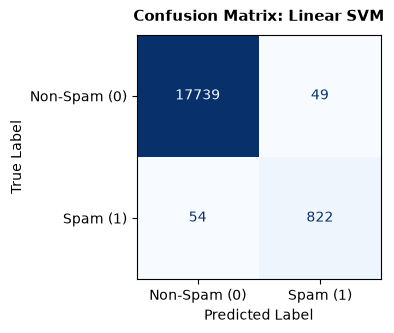

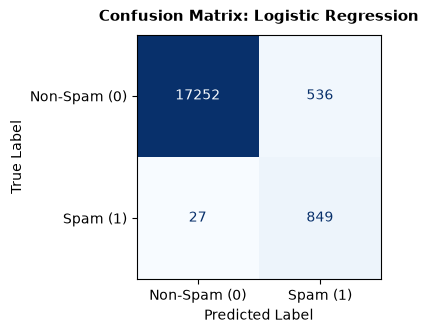

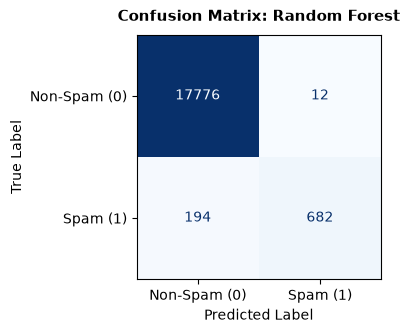

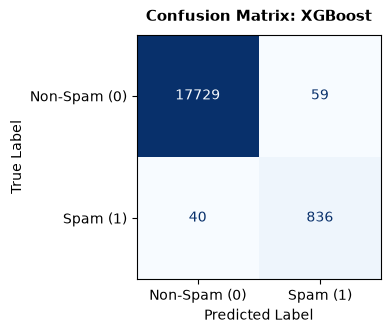

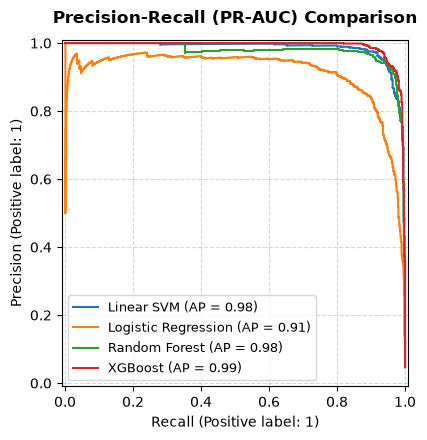

In [49]:
from sklearn.metrics import (
    PrecisionRecallDisplay,
    ConfusionMatrixDisplay,
    average_precision_score,
    classification_report,
    confusion_matrix,
)

# ---------------------------------------------------------
# 4. Plotting Smaller Confusion Matrices for Each Model
# ---------------------------------------------------------
for name, trained_model in trained_models.items():
    fig, ax = plt.subplots(figsize=(4, 4))
    
    ConfusionMatrixDisplay.from_estimator(
        trained_model, 
        X_test_clean, 
        y_test, 
        display_labels=['Non-Spam (0)', 'Spam (1)'],
        cmap='Blues',
        ax=ax,
        colorbar=False
    )
    
    ax.set_title(f"Confusion Matrix: {name}", fontsize=11, fontweight='bold', pad=10)
    ax.set_xlabel("Predicted Label", fontsize=10)
    ax.set_ylabel("True Label", fontsize=10)
    plt.tight_layout()
    plt.show()

# ---------------------------------------------------------
# 5. Plotting a Compact Combined PR-AUC Curve
# ---------------------------------------------------------
fig, ax = plt.subplots(figsize=(6, 4.5))

for name, trained_model in trained_models.items():
    PrecisionRecallDisplay.from_estimator(
        trained_model, 
        X_test_clean, 
        y_test, 
        name=name,
        ax=ax,
        plot_chance_level=(name == "XGBoost (Current Winner)")
    )

ax.set_title("Precision-Recall (PR-AUC) Comparison", fontsize=12, fontweight='bold', pad=12)
ax.legend(loc="lower left", fontsize=9)
ax.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

PR-AUC (Average Precision): 0.9823

Classification Report:
               precision    recall  f1-score   support

           0       1.00      0.99      1.00     17788
           1       0.89      0.96      0.92       876

    accuracy                           0.99     18664
   macro avg       0.94      0.98      0.96     18664
weighted avg       0.99      0.99      0.99     18664



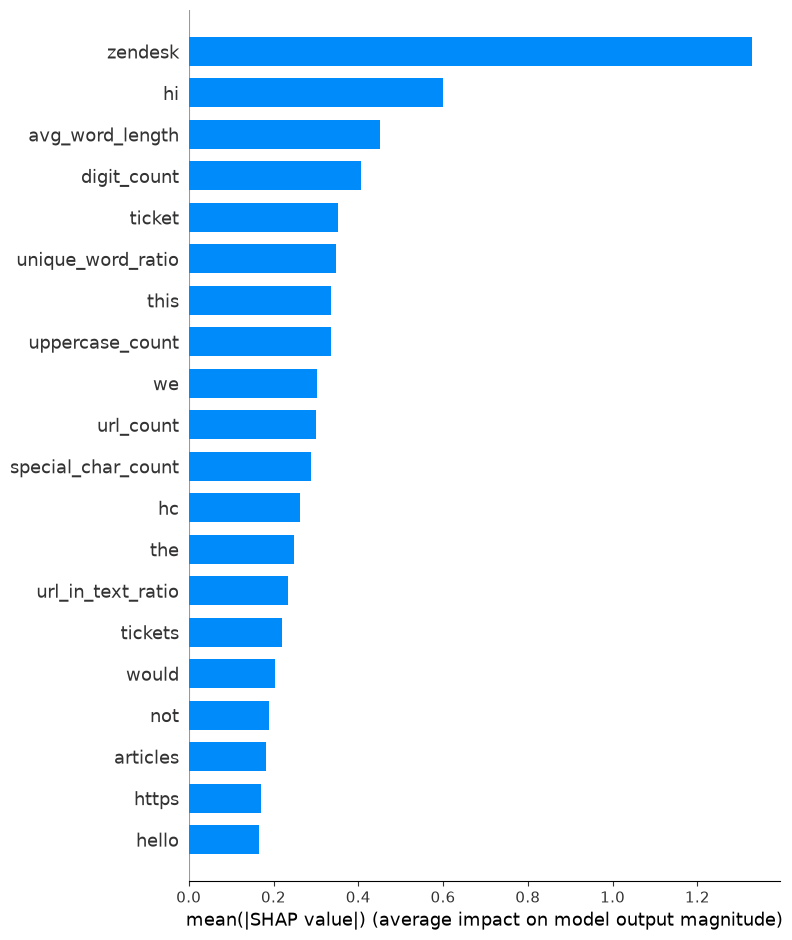

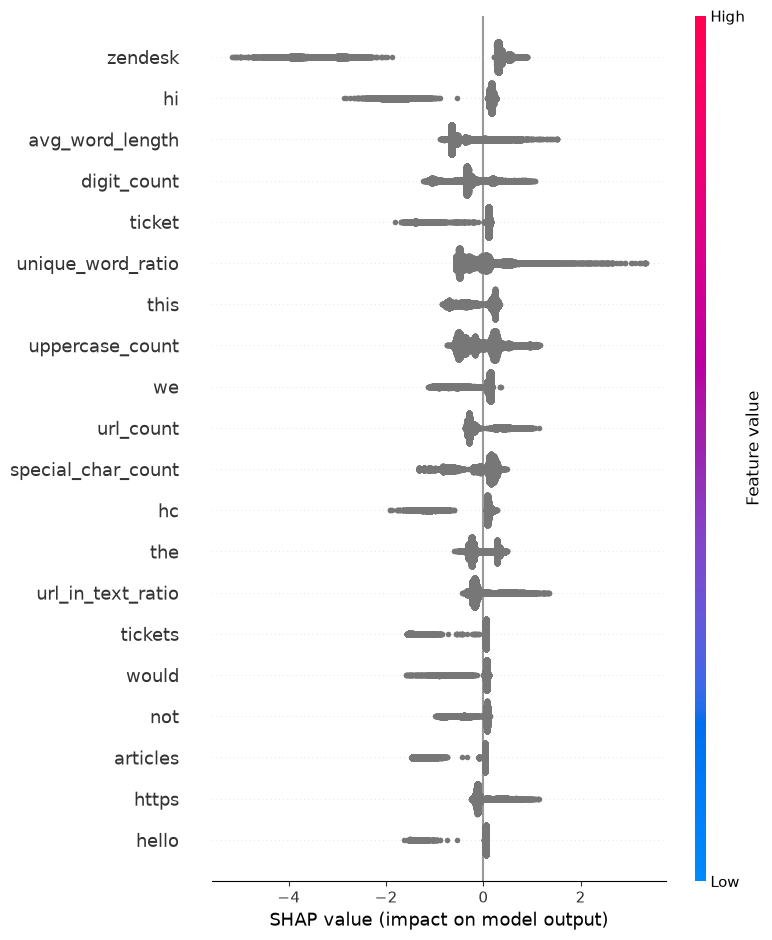

In [52]:
import numpy as np
import pandas as pd
from scipy.sparse import hstack
from sklearn.metrics import average_precision_score, classification_report
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from xgboost import XGBClassifier
import shap

# 1. Define the exact columns you want to select
selected_cols = ['is_spam', 'url_count', 'has_url', 'has_short_url', 'has_ip_url', 'suspicious_tld', 
                 'unique_url_count', 'url_in_text_ratio', 'word_count', 'char_count', 'avg_word_length', 
                 'uppercase_count', 'uppercase_ratio', 'digit_count', 'special_char_count', 'exclamation_count', 
                 'question_count', 'sentence_count', 'unique_word_ratio', 'spam_keyword_count', 'body_english']

# Subset the DataFrame to only these columns
clean_data_filtered = clean_data[selected_cols]

# 2. Separate into features (X) and target prediction (y)
X = clean_data_filtered.drop(columns=['is_spam'])
y = clean_data_filtered['is_spam']

# Fix: Replace NaN values with an empty string and ensure everything is a string
X['body_english'] = X['body_english'].fillna('').astype(str)

# 3. Split data into training (80%) and testing (20%) sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 4. Apply TF-IDF to the cleaned text body
vectorizer = TfidfVectorizer(max_features=5000, ngram_range=(1, 2))
X_train_text = vectorizer.fit_transform(X_train['body_english'])
X_test_text = vectorizer.transform(X_test['body_english'])

# List of numerical feature columns used
num_cols = ['url_count', 'has_url', 'has_short_url', 'has_ip_url', 'suspicious_tld', 
                 'unique_url_count', 'url_in_text_ratio', 'word_count', 'char_count', 'avg_word_length', 
                 'uppercase_count', 'uppercase_ratio', 'digit_count', 'special_char_count', 'exclamation_count', 
                 'question_count', 'sentence_count', 'unique_word_ratio', 'spam_keyword_count']

# 5. Extract numerical features
X_train_num = X_train[num_cols].astype(np.float32).values
X_test_num = X_test[num_cols].astype(np.float32).values

# 6. Combine numerical features and TF-IDF text features into a single sparse matrix
X_train_combined = hstack([X_train_num, X_train_text]).tocsr()
X_test_combined = hstack([X_test_num, X_test_text]).tocsr()

# 7. Initialize and train XGBoost
model = XGBClassifier(
    n_estimators=500,
    max_depth=3,
    learning_rate=0.1,
    scale_pos_weight=5.0,
    random_state=42,
    eval_metric='logloss',
    tree_method='hist',
    max_bin=128,
    n_jobs=2,
)

model.fit(X_train_combined, y_train)

# 8. Evaluation
y_pred_proba = model.predict_proba(X_test_combined)[:, 1]
pr_auc = average_precision_score(y_test, y_pred_proba)
print(f'PR-AUC (Average Precision): {pr_auc:.4f}')

y_pred = model.predict(X_test_combined)
print('\nClassification Report:\n', classification_report(y_test, y_pred))

# ==========================================
# 9. SHAP Feature Interpretability Setup
# ==========================================
# Generate full feature names list matching your combined matrix columns
feature_names = num_cols + list(vectorizer.get_feature_names_out())

# TreeExplainer works natively and efficiently with XGBoost
explainer = shap.TreeExplainer(model)

# Compute SHAP values on a test subset (e.g., first 1000 samples for speed)
#sample_size = min(1000, X_test_combined.shape[0])
#X_test_sample = X_test_combined[:sample_size]

shap_values = explainer(X_test_combined)

# 1. Global Feature Importance Bar Plot (Top 20 features across all test data)
shap.summary_plot(
    shap_values,
    X_test_combined,
    feature_names=feature_names,
    plot_type='bar',
    max_display=20,
)

# 2. Beeswarm Plot (Shows distribution of positive/negative impact for top features)
shap.summary_plot(
    shap_values, X_test_combined, feature_names=feature_names, max_display=20
)